# 4. Inspecting FitLins outputs

**What you will learn**
- How the derivative folder is organised (run / subject / dataset level) and how to parse BIDS-style file names.
- What the statistic maps are (`effect`, `variance`, `t`, `z`, `p`) and how they relate.
- How a result is built up from run-level maps to the group map.

Everything is downloaded on demand from the public OpenNeuro derivatives bucket (each map is about 2 MB). Change
`DATASET`/`TASK` to look at any other study.

In [2]:
import json, re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 140)

# Make `nb_utils` importable whether Jupyter was started in notebooks/ or at the repo root
NB_DIR = Path.cwd() if (Path.cwd() / "nb_utils.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB_DIR))
import nb_utils as nbu

REPO = NB_DIR.parent
SPECS = REPO / "statsmodel_specs"

import nibabel as nib
from IPython.display import Image, display
from nilearn import plotting
from nilearn.interfaces.bids import parse_bids_filename

In [3]:
DATASET = "ds003425"
TASK = "learning"
Z_THRESH = 2.3          # display threshold for z maps
SUBJECT = None          # e.g. "02"; None = first subject found
CONTRAST = None         # e.g. "VCSPvVCSN"; None = first contrast found

## 1. Inventory of the output

One recursive listing of the task's folder gives every file name. Then each name is parsed into its BIDS entities
(subject, session, run, contrast, statistic).

In [4]:
inv = pd.DataFrame(nbu.list_deriv_files(DATASET, TASK))
inv["path"] = inv["key"].str.replace(nbu.deriv_prefix(DATASET, TASK), "", regex=False)
inv["node"] = inv["path"].str.extract(r"^node-(\w+)/")[0].fillna("top level")
inv["is_report"] = inv["path"].str.contains("/reports/|^reports/")
for e in ("sub", "ses", "run", "contrast", "stat"):
    inv[e] = inv["key"].map(lambda k: parse_bids_filename(k).get(e))
inv["tag"] = inv["key"].map(lambda k: parse_bids_filename(k)["file_tag"])
print(f"{len(inv)} files, {inv['size'].sum() / 1e6:.0f} MB")
inv.groupby(["node", "is_report"]).agg(files=("key", "size"), MB=("size", lambda s: round(s.sum() / 1e6, 1)))

1964 files, 2477 MB


files      MB
node         is_report               
dataLevel    False         15    29.4
             True           3     0.5
runLevel     False       1296  2063.6
             True         432    67.1
subjectLevel False        180   309.3
             True          36     6.4
top level    False          1     0.0
             True           1     0.1

In [5]:
maps = inv[inv["tag"] == "statmap"]
pd.crosstab(maps["node"], maps["stat"])

stat,effect,logLikelihood,p,rSquare,t,variance,z
node,,,,,,,
dataLevel,3,0,3,0,3,3,3
runLevel,216,72,216,72,216,216,216
subjectLevel,36,0,36,0,36,36,36


Rows are the three model levels, columns the statistic stored in each map. `rSquare` and `logLikelihood` exist only at run level.

- `node-runLevel/sub-*/ses-*/`: one set of maps per **subject x run** (and `*_design.tsv`).
- `node-subjectLevel/sub-*/`: a fixed-effects average of each subject's runs.
- `node-dataLevel/`: the group map for each contrast.

In [6]:
desc = json.loads(nbu.fetch(nbu.DERIV_BUCKET, nbu.deriv_prefix(DATASET, TASK) + "dataset_description.json").read_text())
print(json.dumps(desc, indent=2)[:1500])

{
  "Name": "Fitlins output",
  "BIDSVersion": "1.1.0",
  "PipelineDescription": {
    "Name": "FitLins",
    "Version": "0.11.0.post0.dev16",
    "CodeURL": "https://github.com/poldracklab/fitlins",
    "Parameters": {
      "bids_dir": "../ds003425",
      "output_dir": "../task-learning",
      "analysis_level": "participant",
      "verbose": 3,
      "quiet": 0,
      "participant_label": null,
      "model": "../ds003425-learning_specs",
      "derivatives": [
        "../derivatives_alt"
      ],
      "derivative_label": null,
      "space": "MNI152NLin2009cAsym",
      "force_index": null,
      "ignore": [
        "sub-.*_physio\\.(json|tsv\\.gz)"
      ],
      "desc_label": "preproc",
      "database_path": null,
      "smoothing": "5:run:iso",
      "n_cpus": 6,
      "mem_gb": 96.0,
      "debug": false,
      "reports_only": false,
      "work_dir": "../task-learning",
      "drop_missing": true,
      "estimator": "nilearn",
      "drift_model": null,
      "error_ts": 

## 2. Group (data-level) maps

One z map per contrast. Unlike the run-level maps these have a single value per voxel for the whole sample.

Contrasts at data level: ['ICSPvICSN', 'VCSPshck', 'VCSPvVCSN']


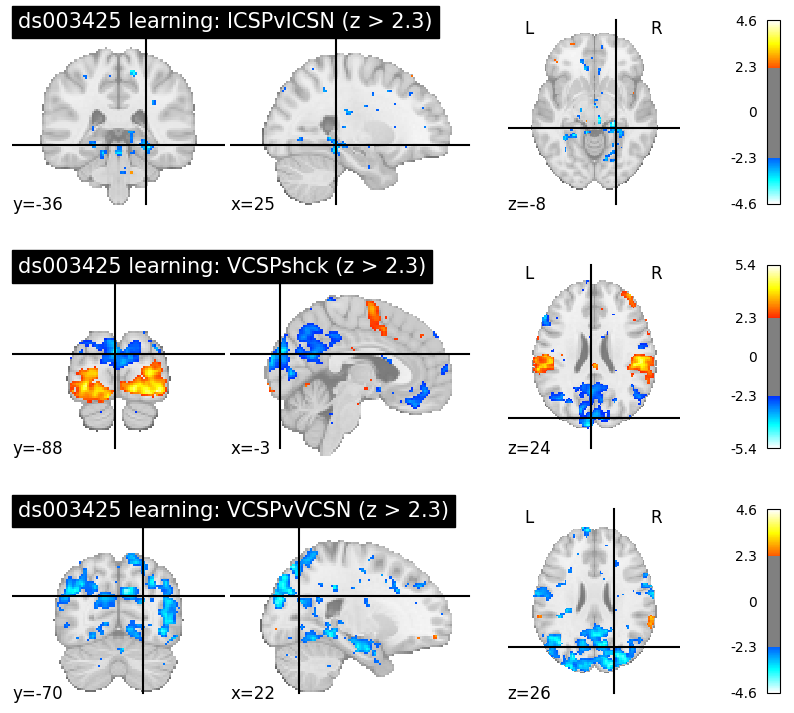

In [7]:
data_z = maps[(maps["node"] == "dataLevel") & (maps["stat"] == "z")].sort_values("contrast")
print("Contrasts at data level:", list(data_z["contrast"]))
show = data_z.head(4)
fig, axes = plt.subplots(len(show), 1, figsize=(10, 3 * len(show)))
for ax, (_, r) in zip(np.atleast_1d(axes), show.iterrows()):
    plotting.plot_stat_map(str(nbu.fetch(nbu.DERIV_BUCKET, r["key"])), threshold=Z_THRESH, axes=ax,
                           title=f"{DATASET} {TASK}: {r['contrast']} (z > {Z_THRESH})", colorbar=True)
plt.show()

## 3. From runs to subjects to the group

Pick one subject and one contrast and follow the same contrast through the three levels.

subject 02, contrast ICSPvICSN: 3 run maps shown


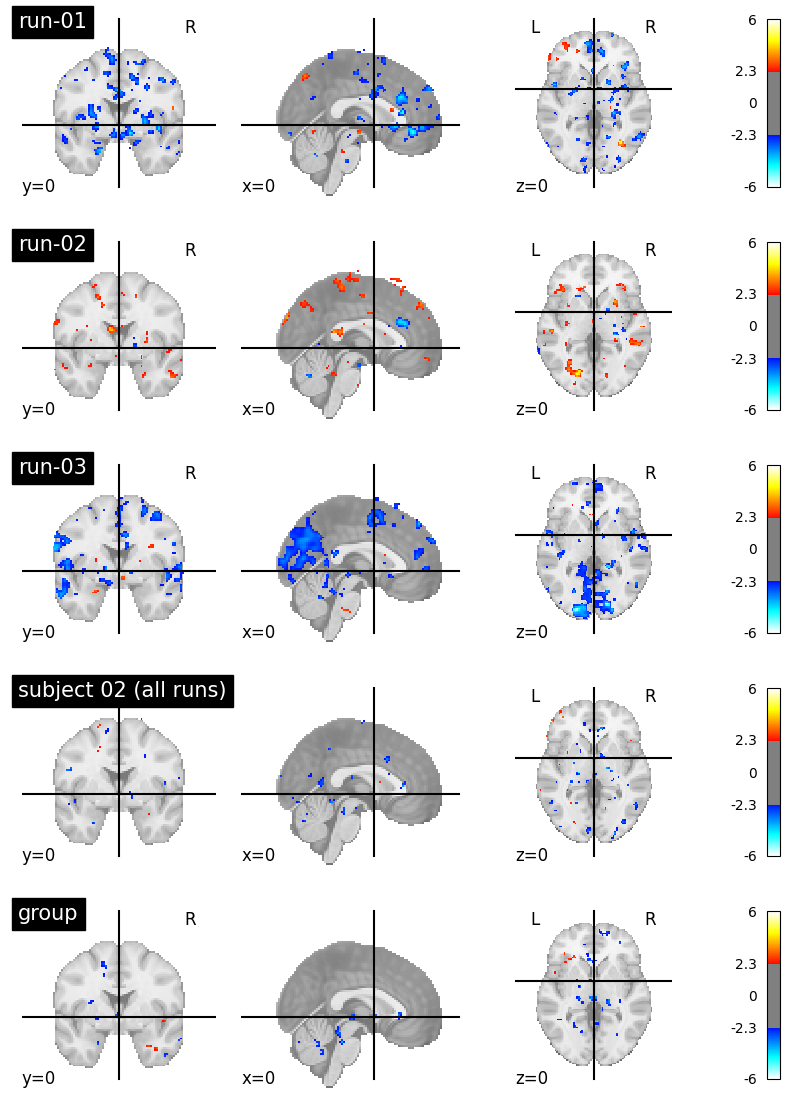

In [8]:
CON = CONTRAST or data_z["contrast"].iloc[0]
subs_with_runs = sorted(maps[(maps["node"] == "runLevel")]["sub"].dropna().unique())
SUB = SUBJECT or subs_with_runs[0]

def pick(node, stat, **kw):
    q = maps[(maps["node"] == node) & (maps["stat"] == stat) & (maps["contrast"] == CON)]
    for k, v in kw.items():
        q = q[q[k] == v]
    return q.sort_values("key")

run_maps = pick("runLevel", "z", sub=SUB).head(3)
subj_map = pick("subjectLevel", "z", sub=SUB).iloc[0]
group_map = pick("dataLevel", "z").iloc[0]
print(f"subject {SUB}, contrast {CON}: {len(run_maps)} run maps shown")

panels = [(f"run-{r['run']}", r["key"]) for _, r in run_maps.iterrows()] + \
         [(f"subject {SUB} (all runs)", subj_map["key"]), ("group", group_map["key"])]
fig, axes = plt.subplots(len(panels), 1, figsize=(10, 2.8 * len(panels)))
for ax, (title, key) in zip(axes, panels):
    plotting.plot_stat_map(str(nbu.fetch(nbu.DERIV_BUCKET, key)), threshold=Z_THRESH, vmax=6, axes=ax,
                           title=title, colorbar=True, cut_coords=(0, 0, 0))
plt.show()

In [9]:
def load(key):
    return nib.load(nbu.fetch(nbu.DERIV_BUCKET, key)).get_fdata().squeeze()

subj_z, grp_z = load(subj_map["key"]), load(group_map["key"])
ok = (subj_z != 0) & (grp_z != 0)
rows = {f"run-{r['run']} vs subject": np.corrcoef(load(r["key"])[ok], subj_z[ok])[0, 1] for _, r in run_maps.iterrows()}
rows["subject vs group"] = np.corrcoef(subj_z[ok], grp_z[ok])[0, 1]
print("Voxelwise correlation of z maps (voxels with data in all maps):")
pd.Series(rows, name="r").round(3).to_frame()

Voxelwise correlation of z maps (voxels with data in all maps):


,r
run-01 vs subject,0.457
run-02 vs subject,0.272
run-03 vs subject,0.452
subject vs group,0.401


A single subject's map is only loosely related to the group map, which is why group results need many subjects.
Runs of the same subject tend to agree more with that subject's average (it contains them).

## 4. What the statistic maps are

For the same subject/contrast, `effect` is the contrast estimate, `variance` its sampling variance, `t = effect / sqrt(variance)`,
`z` is the t value converted to a z score, and `p` the p-value.

t = effect / sqrt(variance): max abs difference = 0.00e+00
z and t correlation: 0.9874 (monotone, similar for large df)


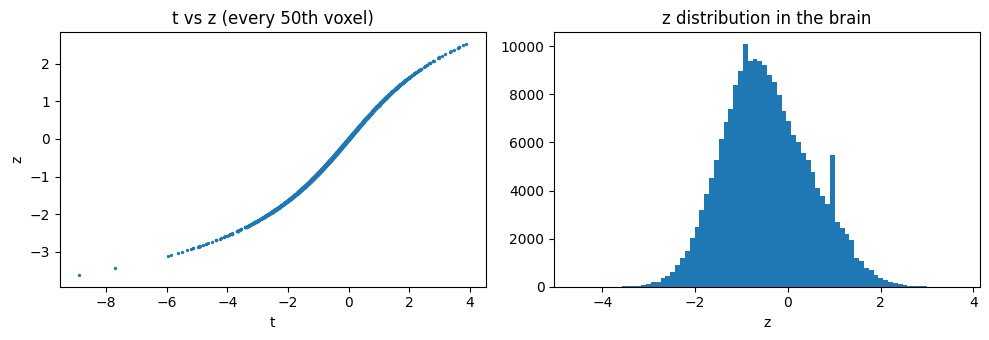

In [10]:
stats = {s: load(pick("subjectLevel", s, sub=SUB).iloc[0]["key"]) for s in ["effect", "variance", "t", "z", "p"]}
m = (stats["variance"] > 0)
t_check = stats["effect"][m] / np.sqrt(stats["variance"][m])
print(f"t = effect / sqrt(variance): max abs difference = {np.abs(t_check - stats['t'][m]).max():.2e}")
print(f"z and t correlation: {np.corrcoef(stats['z'][m], stats['t'][m])[0, 1]:.4f} (monotone, similar for large df)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(stats["t"][m][::50], stats["z"][m][::50], s=2); axes[0].set_xlabel("t"); axes[0].set_ylabel("z")
axes[0].set_title("t vs z (every 50th voxel)")
axes[1].hist(stats["z"][m], bins=80); axes[1].set_title("z distribution in the brain"); axes[1].set_xlabel("z")
plt.tight_layout(); plt.show()

## 5. FitLins' own report figures

FitLins writes quick-look figures next to the maps, such as orthogonal views and the design/contrast plots.

3 data-level report figures


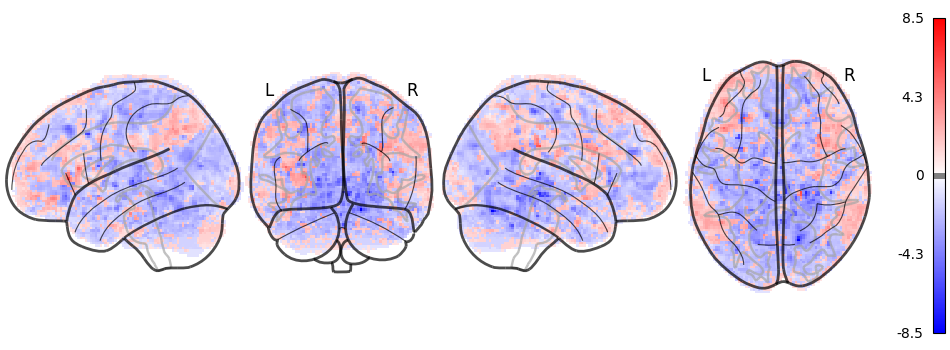

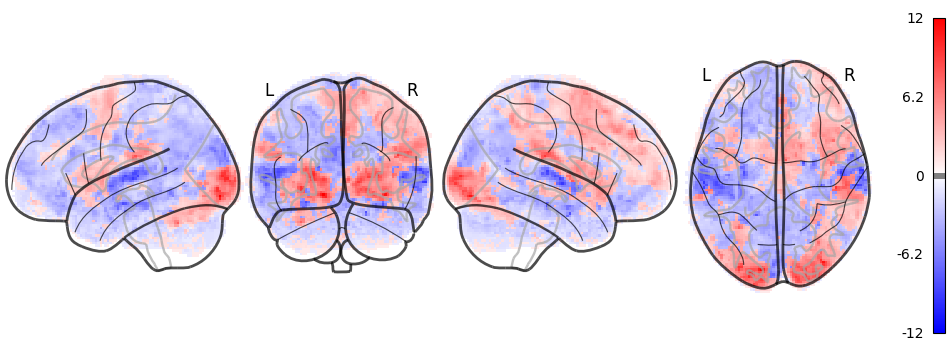

In [11]:
figs = inv[inv["is_report"] & inv["key"].str.endswith(".png") & (inv["node"] == "dataLevel")]
print(f"{len(figs)} data-level report figures")
for key in figs["key"].head(2):
    display(Image(filename=str(nbu.fetch(nbu.DERIV_BUCKET, key))))

**Next:** [05_group_report_walkthrough.ipynb](05_group_report_walkthrough.ipynb)